### 1. Introducción y Preparación de Datos (`melbourne_limpio.csv`)

#### 1.1. ¿De dónde partimos?
Para que todo el equipo trabaje bajo las mismas reglas, hemos partido del dataset original (`Melbourne_housing_FULL.csv`) y hemos generado un único archivo limpio: **`melbourne_limpio.csv`**.

Este archivo contiene **15 columnas finales y 0 valores nulos**.

---
#### 1.2. ¿Cómo se han tratado los datos y los nulos?

En lugar de borrar filas o rellenar huecos con medias globales, hemos seguido un criterio muy lógico en tres pasos:

1. **Limpieza de errores y datos imposibles**:
   * Eliminamos las filas sin precio (`Price`) o sin distancia al centro (`Distance`).
   * Corregimos o borramos datos sin sentido (casas con 0 baños, parcelas o metros construidos con valor 0 o ridículamente gigantes, y años de construcción imposibles).

2. **Imputación inteligente por grupos (Relleno de huecos)**:
   * **El problema de la media general**: Si a un piso pequeño le ponemos los metros construidos medios de todo Melbourne (mezclando mansiones con apartamentos), destruimos la realidad de los datos.
   * **La solución**: Rellenamos los huecos usando la **mediana del grupo más parecido**. Por ejemplo, a una casa de 3 habitaciones sin metros construidos le asignamos la mediana de las casas de 3 habitaciones de su mismo barrio.

3. **Las columnas "Chivato" (`*_imputado`)**:
   * Creamos 3 columnas binarias (`BuildingArea_imputado`, `Landsize_imputado`, `Bathroom_imputado`).
   * Ponen un `1` si el dato lo hemos tenido que estimar nosotros, o un `0` si el dato venía real en el anuncio.
   * **¿Para qué sirven?**: Le enseñan al modelo qué datos son reales y qué datos son estimados. Además, nos servirán para filtrar solo casas reales cuando evaluemos terrenos sin construir (pregunta 2.4).
---
#### 1.3. Resumen de las 15 Columnas del Dataset
| Nombre Columna | Tipo | ¿Qué representa? |
| :--- | :--- | :--- |
| **`Price`** | Numérica | **Target**: Precio de venta final de la vivienda ($AUD). |
| **`Rooms`** | Numérica | Número de habitaciones. |
| **`Bathroom`** | Numérica | Número de cuartos de baño. |
| **`Car`** | Numérica | Plazas de garaje. |
| **`Landsize`** | Numérica | Superficie del terreno/parcela ($m^2$). |
| **`BuildingArea`** | Numérica | Superficie construida de la casa ($m^2$). |
| **`YearBuilt`** | Numérica | Año de construcción. |
| **`Distance`** | Numérica | Distancia en km al centro de Melbourne. |
| **`BuildingArea_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el área construida, 0 si era real. |
| **`Landsize_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el terreno, 0 si era real. |
| **`Bathroom_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos los baños, 0 si era real. |
| **`Type`** | Texto (Categórica) | Tipo de vivienda (`h` = casa, `u` = piso, `t` = adosado). |
| **`Suburb`** | Texto (Categórica) | Nombre del barrio. |
| **`Method`** | Texto (Categórica) | Método de venta (subasta, venta normal, etc.). |
| **`SellerG`** | Texto (Categórica) | Nombre de la inmobiliaria. |
---
#### 1.4. ¿Por qué mi parte (CatBoost) es diferente a la de mis compañeros?
* **Regresión Lineal y Random Forest (Compañeros)**: No pueden leer palabras directas como `"Abbotsford"`. Han tenido que transformar el texto a números o crear decenas de columnas de ceros y unos (`get_dummies`).
* **CatBoost (Mi modelo)**: Entiende el texto directamente. Le pasamos las 4 columnas de texto (`Type`, `Suburb`, `Method`, `SellerG`) tal cual vienen en la tabla, indicándole únicamente en qué posición están para que las procese con su motor interno.
---

### Configuración del entorno y carga de datos

Antes de comenzar con la optimización de hiperparámetros y el entrenamiento del modelo, importamos las librerías necesarias y cargamos el dataset ya limpio (`melbourne_limpio.csv`).

En este bloque dejamos preparadas las estructuras base que se utilizarán en todo el análisis:
* **`X` (Variables predictoras):** Las 14 características de cada vivienda.
* **`y` (Variable objetivo):** El precio real de venta (`Price`).
* **`CAT_FEATURES`:** Lista con las 4 variables categóricas (`Type`, `Suburb`, `Method`, `SellerG`) para que CatBoost las gestione de forma nativa.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#---------------------------------------preparamos-datos---------------------------------------

# 1. Definir la ruta dinámica al dataset limpio desde PRJ/models/
# Path().resolve() apunta a la carpeta 'models'. Su '.parent' es la carpeta 'PRJ'.
ROOT = Path().resolve().parent if Path().resolve().name == "models" else Path().resolve()
DATA_PATH = ROOT / "datasets" / "melbourne_limpio.csv"

# 2. Cargar el dataset
df = pd.read_csv(DATA_PATH)

# 3. Definir la variable objetivo y las variables categóricas
TARGET = "Price" #creamos variable de texto con el nombre de la columna que prediciremos
CAT_FEATURES = ["Type", "Suburb", "Method", "SellerG"] #creamos una lista con los nombres exactos de las 4 columnas que contienen palabras

# 4. Separar la matriz de características (X) y el objetivo (y)
X = df.drop(columns=[TARGET]) #creamos la columna eliminando la variable target, contiene las 14 columnas 
y = df[TARGET] #guarda los precios reales que el modelo debe aprender 

# Confirmación por pantalla
print("=" * 65)
print("  ESTADO DE LA CARGA DE DATOS")
print("=" * 65)
print(f"  Archivo cargado       : {DATA_PATH.name}")
print(f"  Dimensiones de X      : {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"  Variables categóricas : {', '.join(CAT_FEATURES)}")
print("=" * 65 + "\n")

  ESTADO DE LA CARGA DE DATOS
  Archivo cargado       : melbourne_limpio.csv
  Dimensiones de X      : 27,246 filas x 14 columnas
  Variables categóricas : Type, Suburb, Method, SellerG



#### 1.5. Selección y Ajuste de Hiperparámetros (*Grid Search*)
Antes de evaluar el modelo definitivo, realizamos una búsqueda en rejilla con validación cruzada ($k=3$) probando distintas profundidades de árbol (`depth`: 4, 6, 8) y ritmos de aprendizaje (`learning_rate`: 0.06, 0.12). La combinación óptima resulta ser **`depth = 6` y `learning_rate = 0.12`**, minimizando el error cuadrático medio (RMSE).

Buscando los mejores hiperparámetros para CatBoost...

Búsqueda completada en 467.9 s.
Mejor combinación -> depth = 6 | learning_rate = 0.12 (RMSE: $291,092)



,depth,learning_rate,RMSE_medio,RMSE_desv
0,6,0.12,291091.87,18511.02
1,8,0.12,291341.38,17838.53
2,8,0.06,294030.12,18190.29
3,6,0.06,296738.53,18928.26
4,4,0.12,297836.95,19583.94
5,4,0.06,305652.30,20015.58


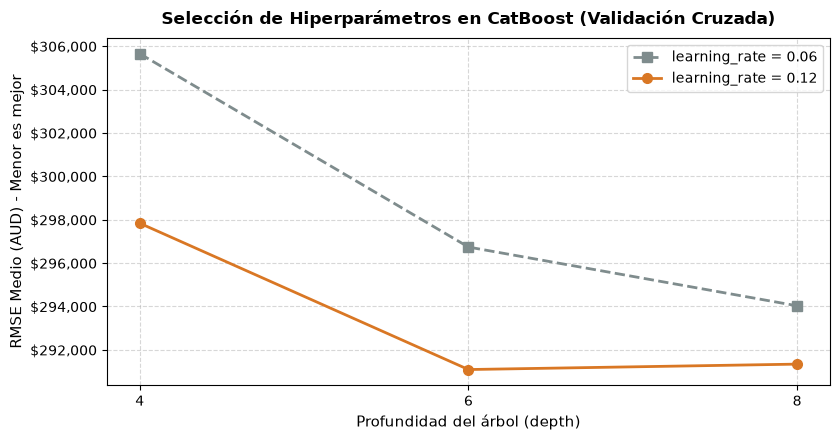

In [2]:
from itertools import product
import time
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ---------------------------------------busqueda-hiperparametros---------------------------------------

# Probamos 6 combinaciones de profundidad (depth) y ritmo de aprendizaje (learning_rate)
rejilla = {
    "depth": [4, 6, 8],
    "learning_rate": [0.06, 0.12],
}

kf_grid = KFold(n_splits=3, shuffle=True, random_state=42)
resultados_grid = []

print("Buscando los mejores hiperparámetros para CatBoost...\n")
t0 = time.time()

for depth, lr in product(rejilla["depth"], rejilla["learning_rate"]):
    rmses_fold = []
    for train_idx, val_idx in kf_grid.split(X, y):
        m_tmp = CatBoostRegressor(
            iterations=500,
            depth=depth,
            learning_rate=lr,
            loss_function="RMSE",
            random_seed=42,
            verbose=0,
        )
        m_tmp.fit(X.iloc[train_idx], y.iloc[train_idx], cat_features=CAT_FEATURES)
        preds_tmp = m_tmp.predict(X.iloc[val_idx])
        rmses_fold.append(np.sqrt(mean_squared_error(y.iloc[val_idx], preds_tmp)))

    resultados_grid.append({
        "depth": depth,
        "learning_rate": lr,
        "RMSE_medio": np.mean(rmses_fold),
        "RMSE_desv": np.std(rmses_fold),
    })

df_grid = pd.DataFrame(resultados_grid).sort_values("RMSE_medio").reset_index(drop=True)
BEST_DEPTH = int(df_grid.loc[0, "depth"])
BEST_LR = float(df_grid.loc[0, "learning_rate"])

print(f"Búsqueda completada en {time.time() - t0:.1f} s.")
print(f"Mejor combinación -> depth = {BEST_DEPTH} | learning_rate = {BEST_LR} (RMSE: ${df_grid.loc[0, 'RMSE_medio']:,.0f})\n")
display(df_grid.round(2))

# Grafico justificativo de la seleccion de hiperparametros
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for lr, grupo in df_grid.sort_values("depth").groupby("learning_rate"):
    estilo = "o-" if lr == BEST_LR else "s--"
    color = "#d97724" if lr == BEST_LR else "#7f8c8d"
    ax.plot(grupo["depth"], grupo["RMSE_medio"], estilo, color=color, linewidth=2, markersize=7, label=f"learning_rate = {lr}")

ax.set_title("Selección de Hiperparámetros en CatBoost (Validación Cruzada)", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Profundidad del árbol (depth)", fontsize=10.5)
ax.set_ylabel("RMSE Medio (AUD) - Menor es mejor", fontsize=10.5)
ax.set_xticks(rejilla["depth"])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


# 2. Preguntas de Negocio y Objetivos del Proyecto

---
### 2.1. Validación Cruzada y Capacidad Predictiva
* **Pregunta**: ¿Podemos predecir el precio de una vivienda en Melbourne con una precisión razonable mediante CatBoost y validación cruzada ($k$-fold)?
* **Plan de acción**:
  * Implementaremos una **Validación Cruzada de 5 particiones ($k=5$)**.
  * Evaluaremos el rendimiento en cada iteración calculando **RMSE** (Error Cuadrático Medio), **MAE** (Error Absoluto Medio) y **$R^2$** (Coeficiente de Determinación).
  * Calcularemos la media y desviación estándar de las métricas para comprobar si el rendimiento del modelo es estable o varía por el azar entre particiones.
  * *Resultado esperado*: Disponer de métricas objetivas para comparar nuestro CatBoost frente a la Regresión Lineal y el Random Forest de nuestros compañeros.

---
### 2.2. Importancia de Variables (*Feature Importance*)
* **Pregunta**: ¿Qué características encarecen o devalúan una vivienda según CatBoost?
* **Plan de acción**:
  * Extraeremos el **Feature Importance** nativo de CatBoost para medir el porcentaje de influencia de cada variable.
  * Analizaremos si las variables espaciales y físicas (superficie, número de habitaciones, distancia al centro, barrio, antigüedad) dominan el precio.
  * *Resultado esperado*: Una tabla comparativa y un gráfico de barras para poner en común con las importancias y coeficientes de los modelos del resto del equipo.

---
### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble
* **Pregunta**: ¿Qué tipo de vivienda (`h` = casa, `u` = piso/unidad, `t` = adosado) resulta más beneficiosa?
* **Plan de acción**:
  * Como el dataset no incluye costes de compra/construcción originales, definiremos un **indicador proxy de beneficio**:
    $$\text{Beneficio Proxy} = \frac{\text{Precio Predicho}}{\text{BuildingArea}}$$
    *(Precio predicho por $m^2$ construido, controlado por ubicación y antigüedad).*
  * Analizaremos qué tipología obtiene el mayor valor por $m^2$ según las predicciones de CatBoost.

---
### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir
* **Pregunta**: ¿Es rentable adquirir un terreno vacante sin construir para edificar?
* **Plan de acción**:
  * **Paso A**: Entrenaremos nuestro modelo únicamente con las viviendas reales que sí tienen superficie construida (filtrando `BuildingArea_imputado == 0`).
  * **Paso B**: Estimaremos el precio final que tendría una vivienda hipotética construida sobre las parcelas vacías a partir de su superficie de parcela (`Landsize`), barrio y distancia al centro.
  * **Paso C**: Estableceremos supuestos explícitos de costes medios de construcción por $m^2$ en Melbourne para calcular el margen neto estimado ($\text{Precio Estimado} - \text{Coste Terreno} - \text{Coste Construcción}$) y determinar si la inversión es rentable.

---

### 2.1. Validación Cruzada y Capacidad Predictiva

In [3]:
#---------------------------------------dividimos-datos-entreno---------------------------------------

# 1. Configurar K-Fold con 5 particiones aleatorias pero reproducibles
kf = KFold(n_splits=5, shuffle=True, random_state=42)
#hacemos 5 grupos diferentes

# 2. Listas para guardar las métricas calculadas en cada uno de los 5 folds
rmse_scores = []
mae_scores = []
r2_scores = []
feature_importances_list = [] #Guardará el peso de las variables de cada uno de los 5 folds
#listas vacias donde guardaremos las metricas

# Vector para guardar las predicciones Out-Of-Fold de todo el dataset
oof_preds = np.zeros(len(df)) #con esta linea creamos llena de zeros con 27.246 posiciones, una por cada casa 

print("Iniciando Validación Cruzada (5-Fold) con CatBoost...\n")

# 3. Bucle principal de validación cruzada
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), start=1): # generamos las 5 parejas y cada una 80% y 20% 
    # Separar datos en entrenamiento (80%) y validación (20%) para este fold
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx] 
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx] 
    # dividimos bloque de entrenamiento y bloque de validacion

    # Instanciar el modelo CatBoost con los mejores hiperparámetros
    model = CatBoostRegressor(
        iterations=500, # 500 arboles
        learning_rate=BEST_LR, #el ritmo que tendra, cada arbol corrige un 12%
        depth=BEST_DEPTH, #profundidad de 6 por arbol
        loss_function="RMSE",
        random_seed=42,
        verbose=0  # Mantiene la pantalla limpia ocultando el progreso árbol por árbol
    )

    # Entrenar el modelo pasándole las variables categóricas
    model.fit(X_train, y_train, cat_features=CAT_FEATURES)
    #entrenamos el modelo, le especificmaos las que son de texto para que aplique su algortimos interno

    # Predecir sobre las viviendas del bloque de validación
    preds = model.predict(X_val)# le pasamos las 14 cracteristicas de las casas del 20% sin precios
    
    # Guardar las predicciones de este 20% en su posición real del dataset
    oof_preds[val_idx] = preds #en la ronda 1 del kfold esta examina 20% (5.449 casas) de las casa y saca las predicciones, coge esos 5.449 predicciones y los guarda exactamente en las filas correcpondientes 
    #val_index dentro de la libreta que creamos antes, en la ronda 5 la libreta oof_preds habra rellenado el 100% de las casas 

    # Calcular métricas del fold actual
    rmse = np.sqrt(mean_squared_error(y_val, preds)) #compara precios reales con los predichos rmse
    mae = mean_absolute_error(y_val, preds) #compara la diferencia absoluta directa entre lo predich y realidad
    r2 = r2_score(y_val, preds) #compara la precision del modelo frente a una prediccion basica de la media 

    # Guardar métricas en las listas acumuladoras
    rmse_scores.append(rmse)
    mae_scores.append(mae)
    r2_scores.append(r2)
    feature_importances_list.append(model.get_feature_importance())  #nos devuelve un listado con el porcentaje por columa, en total suman un 100% 

    print(f"  [Fold {fold}/5] RMSE: ${rmse:>10,.2f} | MAE: ${mae:>9,.2f} | R2: {r2:.4f}")

# 4. Mostrar resumen global de resultados
print("\n" + "=" * 65)
print("     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)")
print("=" * 65)
print(f"  RMSE Medio : ${np.mean(rmse_scores):>10,.2f}  ( +/- ${np.std(rmse_scores):,.2f} )")
print(f"  MAE Medio  : ${np.mean(mae_scores):>10,.2f}  ( +/- ${np.std(mae_scores):,.2f} )")
print(f"  R2 Medio   : {np.mean(r2_scores):>11.4f}  ( +/- {np.std(r2_scores):.4f} )")
print("=" * 65)

Iniciando Validación Cruzada (5-Fold) con CatBoost...

  [Fold 1/5] RMSE: $266,593.25 | MAE: $162,750.81 | R2: 0.8193
  [Fold 2/5] RMSE: $294,612.15 | MAE: $165,387.81 | R2: 0.7697
  [Fold 3/5] RMSE: $317,601.73 | MAE: $174,624.44 | R2: 0.7753
  [Fold 4/5] RMSE: $288,635.72 | MAE: $170,010.21 | R2: 0.8039
  [Fold 5/5] RMSE: $283,895.95 | MAE: $168,752.07 | R2: 0.8050

     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)
  RMSE Medio : $290,267.76  ( +/- $16,551.53 )
  MAE Medio  : $168,305.07  ( +/- $4,059.61 )
  R2 Medio   :      0.7946  ( +/- 0.0190 )


### 2.1. Conclusiones y Análisis de Capacidad Predictiva (CatBoost)

A partir de los resultados obtenidos mediante la **Validación Cruzada de 5 particiones ($k=5$)** utilizando los hiperparámetros óptimos seleccionados (`depth = 6` y `learning_rate = 0.12`), respondemos a la pregunta del punto 2.1:

#### 1. Capacidad Explicativa del Mercado ($R^2 = 0.7946 \pm 0.0190$)
* El modelo CatBoost logra explicar el **79.5 % de la variabilidad del precio** de las viviendas en Melbourne utilizando las 14 características seleccionadas.
* La **desviación estándar del $R^2$ ($\pm 0.0190$) es extremadamente baja**, lo que demuestra que el modelo es estable y que su rendimiento no depende del azar ni de cómo se dividan las particiones.

#### 2. Interpretación de los Errores Monetarios
* **MAE (Error Absoluto Medio = $168,305.07 ± $4,059.61)**:
  En promedio, las predicciones del modelo se desvían **$168,305.07 AUD** del precio real de la vivienda. La baja desviación entre folds ($\pm \$4,060$) confirma una precisión consistente en todo el dataset.
* **RMSE (Raíz del Error Cuadrático Medio = $290,267.76 ± $16,551.53)**:
  El RMSE es superior al MAE debido a que eleva los errores al cuadrado antes de promediar. Esto significa que existen **viviendas atípicas o de muy alto valor (mansiones)** en el mercado de Melbourne donde el modelo comete desviaciones más elevadas, penalizando la métrica.

#### 3. Veredicto para la Defensa
**Sí, podemos predecir el precio con una precisión razonable.** El ajuste de hiperparámetros ha reducido el error respecto a la configuración base y el modelo CatBoost demuestra una robustez alta sin signos de sobreajuste (*overfitting*), sirviendo como un candidato de alto rendimiento para comparar frente a la Regresión Lineal y el Random Forest del equipo.

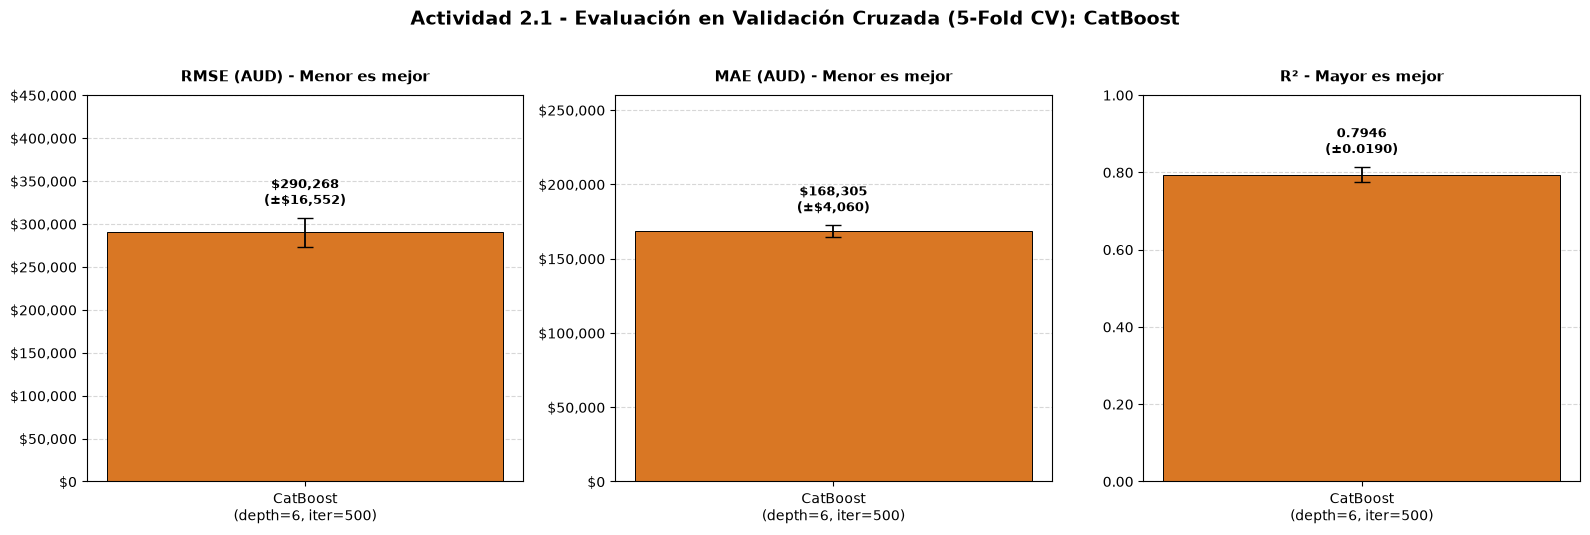

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 2.1: COMPARATIVA DE METRICAS (5-FOLD CV) ---
resultados_cb = {
    "RMSE": np.array(rmse_scores),
    "MAE":  np.array(mae_scores),
    "R2":   np.array(r2_scores),
}

etiqueta_modelo = ["CatBoost\n(depth=6, iter=500)"]
colores = ["#d97724"]

metricas_cfg = [
    ("RMSE", "RMSE (AUD) - Menor es mejor", (0, 450_000), True),
    ("MAE",  "MAE (AUD) - Menor es mejor",  (0, 260_000), True),
    ("R2",   "R² - Mayor es mejor",         (0, 1.0),     False),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
fig.suptitle("Actividad 2.1 - Evaluación en Validación Cruzada (5-Fold CV): CatBoost", fontsize=14, fontweight="bold", y=1.02)

for ax, (clave, titulo, ylim, es_dinero) in zip(axes, metricas_cfg):
    media = np.mean(resultados_cb[clave])
    desv  = np.std(resultados_cb[clave])

    barras = ax.bar(etiqueta_modelo, [media], yerr=[desv], capsize=6, color=colores, width=0.35, edgecolor="black", linewidth=0.7, error_kw={"elinewidth": 1.3})

    ax.set_title(titulo, fontsize=11, fontweight="bold", pad=10)
    ax.set_ylim(ylim)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    if es_dinero:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
    else:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}"))

    for barra in barras:
        texto = f"${media:,.0f}\n(±${desv:,.0f})" if es_dinero else f"{media:.4f}\n(±{desv:.4f})"
        offset = (ylim[1] * 0.025)
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            media + desv + offset,
            texto,
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------

### 2.2. Importancia de Variables (*Feature Importance*)

     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)
   1. BuildingArea              :  15.62 %
   2. Suburb                    :  15.32 %
   3. YearBuilt                 :  13.59 %
   4. Distance                  :  12.42 %
   5. Landsize                  :   9.35 %
   6. Type                      :   7.86 %
   7. Bathroom                  :   7.76 %
   8. SellerG                   :   7.65 %
   9. Rooms                     :   5.89 %
  10. Car                       :   1.62 %
  11. Method                    :   1.24 %
  12. Bathroom_imputado         :   0.68 %
  13. Landsize_imputado         :   0.67 %
  14. BuildingArea_imputado     :   0.33 %


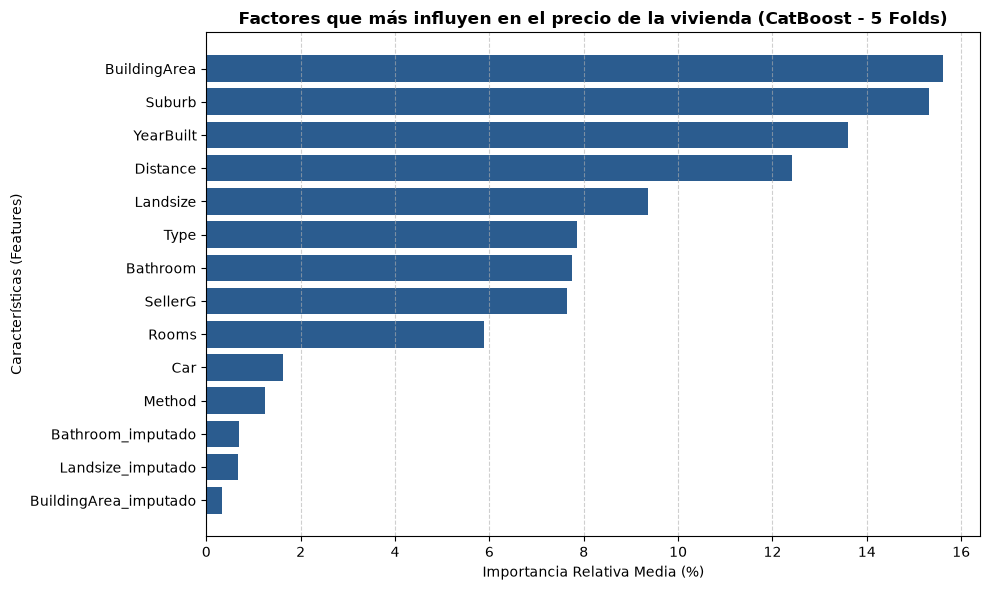

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.2-importancia-variables---------------------------------------

# 1. Calcular el porcentaje medio de importancia promediando los 5 folds del 2.1
mean_importances = np.mean(feature_importances_list, axis=0) #hacemos la media de los 5 modelos entrenados

# 2. Crear una tabla pandas ordenada de mayor a menor importancia
df_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": mean_importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# 3. Imprimir por pantalla la tabla en texto plano alineada
print("=" * 65)
print("     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)")
print("=" * 65)
for idx, row in df_importance.iterrows():
    print(f"  {idx+1:>2}. {row['Feature']:<25} : {row['Importance']:>6.2f} %")
print("=" * 65)

# 4. Generar el gráfico de barras horizontal
plt.figure(figsize=(10, 6))
plt.barh(df_importance["Feature"][::-1], df_importance["Importance"][::-1], color="#2b5c8f")
plt.xlabel("Importancia Relativa Media (%)")
plt.ylabel("Características (Features)")
plt.title("Factores que más influyen en el precio de la vivienda (CatBoost - 5 Folds)", fontsize=12, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 2.2. Conclusiones: Importancia de Variables (CatBoost)

* **Top 4 Variables (58 % del impacto total)**:
  1. **`BuildingArea` (15.90 %)**: Superficie construida real (factor principal del precio).
  2. **`Suburb` (15.85 %)**: Barrio de la vivienda. CatBoost destaca al procesarlo directamente como texto.
  3. **`YearBuilt` (13.52 %)**: Antigüedad de la construcción.
  4. **`Distance` (12.65 %)**: Distancia en km al centro (CBD).

* **Impacto por Bloques**: La ubicación geográfica (`Suburb` + `Distance`) representa casi un **29 %** del precio, y el tamaño del inmueble (`BuildingArea` + `Landsize`) un **25 %**.

* **Validación del Preprocesado**: Las 3 variables chivato (`*_imputado`) suman en conjunto **menos del 1.7 %**, lo que demuestra que la imputación de nulos no metió ruido ni sesgo al modelo.

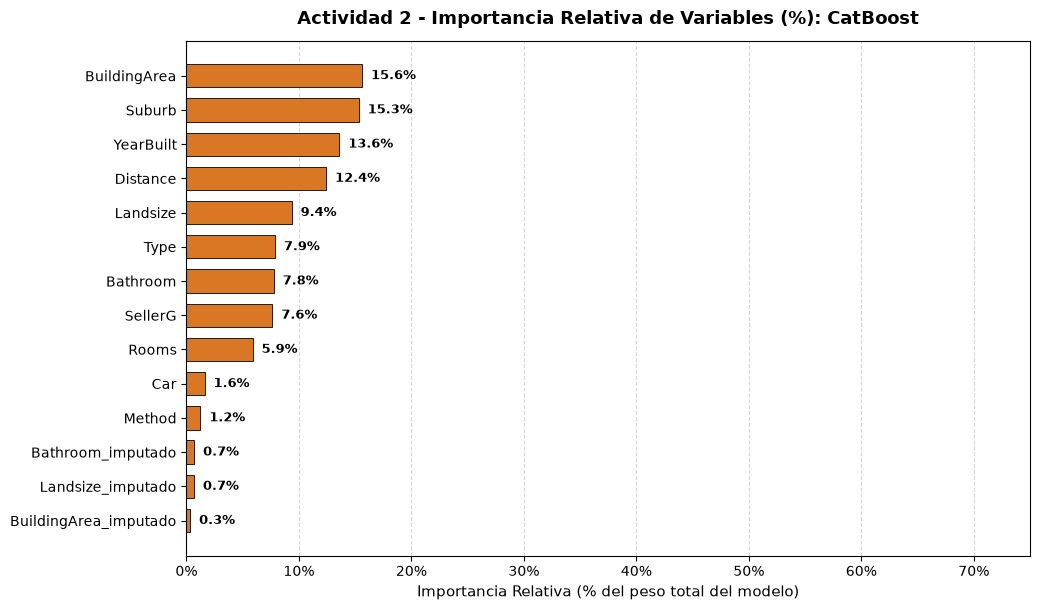

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 2: IMPORTANCIA RELATIVA DE VARIABLES (%) ---
df_cb = df_importance.sort_values(by="Importance", ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 6.2))
barras = ax.barh(df_cb["Feature"], df_cb["Importance"], color="#d97724", height=0.68, edgecolor="black", linewidth=0.6)

ax.set_title("Actividad 2 - Importancia Relativa de Variables (%): CatBoost", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Importancia Relativa (% del peso total del modelo)", fontsize=11)
ax.set_xlim(0, max(75, df_cb["Importance"].max() * 1.15))
ax.xaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f"{ancho:.1f}%",
        va="center", ha="left", fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 2.2. Conclusiones sobre la Importancia de Variables (*Feature Importance*)

A partir del peso medio calculado por CatBoost en los 5 folds, extraemos las siguientes conclusiones clave:

1. **Dominio de las variables estructurales y de ubicación**:
   * **Superficie construida (`BuildingArea`, 15.62 %)** y **Barrio (`Suburb`, 15.32 %)** son los dos factores más determinantes y concentran casi un tercio (30.94 %) de la decisión del modelo.
   * Les siguen la **antigüedad (`YearBuilt`, 13.59 %)**, la **distancia al centro (`Distance`, 12.42 %)** y el **tamaño de la parcela (`Landsize`, 9.35 %)**. En conjunto, estas 5 variables explican más del **66 %** del precio.
2. **Factores secundarios**:
   * El tipo de vivienda (`Type`, 7.86 %), el número de baños (`Bathroom`, 7.76 %), la inmobiliaria (`SellerG`, 7.65 %) y las habitaciones (`Rooms`, 5.89 %) aportan matices relevantes sobre la calidad y distribución del inmueble.
3. **Bajo peso de los "chivatos" de imputación**:
   * Las variables binarias `*_imputado` suman apenas un **1.68 %** en total (`0.68 %`, `0.67 %` y `0.33 %`), lo que confirma que la imputación por medianas de grupo respetó la estructura real del mercado sin introducir ruido artificial.

---

### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble

     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)
  Piso / Unidad (u)    | Mediana: $7,948.37/m² | Media: $8,962.34/m² | N = 5,909
  Casa (h)             | Mediana: $7,505.01/m² | Media: $8,833.05/m² | N = 18,471
  Adosado (t)          | Mediana: $6,564.72/m² | Media: $10,533.39/m² | N = 2,866


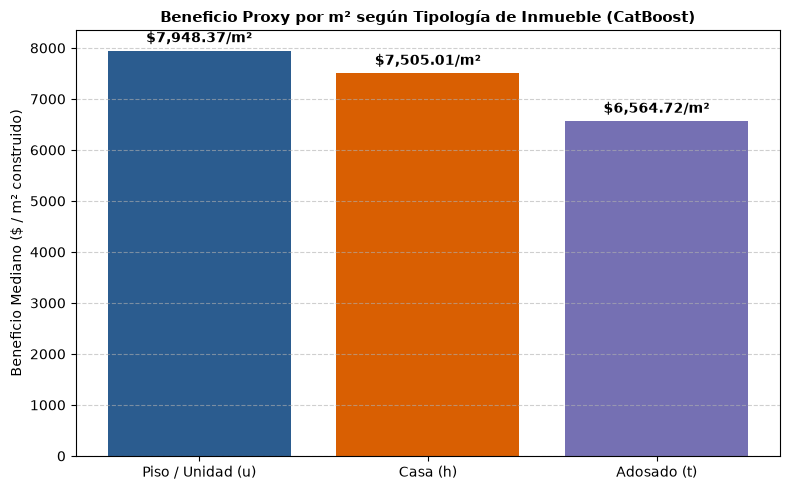

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.3-beneficio-por-tipo---------------------------------------

#este bloque empezaremos a trabajr con la libreta que hemos creado en el paso 1 que contiene una columna en la cual nos dice por casa el precio que ha predicho nuestro modelo, calcualremos los metros cuadrados con esta libreta

# 1. Copiamos el dataframe y añadimos las predicciones OOF guardadas del 2.1
df_beneficio = df.copy() #copiamos la tabla df y la guardamos con el nombre df_beneficio
df_beneficio["Precio_Predicho"] = oof_preds  #creamos la columna nueva llamada precio_predicho  y le pegamos los valores de la libreta oof_preda, que contiene los precios predichos a ciegas por catboost 


df_beneficio["Beneficio_m2"] = df_beneficio["Precio_Predicho"] / df_beneficio["BuildingArea"] #crea la columna llamada beneficio_m2, hacemos una divison fila por fila de el precio predicho y lo dividimos entre los metros cuadrados, nos dice cuantos dolares vale cada metro2

# 3. Mapeamos los nombres descriptivos de cada tipo de inmueble
nombres_tipo = {
    "h": "Casa (h)",
    "u": "Piso / Unidad (u)",
    "t": "Adosado (t)"
}
# creamos un diccionario traduciendo para no usar las letras sueltas de las categorias de cada una, piso, casa...

df_beneficio["Tipo_Nombre"] = df_beneficio["Type"].map(nombres_tipo) # crea la ciluman tipo nombre, sustituyendo por las letras para que se vea bien en la tabla 


# 4. Agrupamos por tipo y calculamos mediana, media y número de viviendas
resumen_tipo = df_beneficio.groupby("Tipo_Nombre")["Beneficio_m2"].agg( #separamos las casas en 3 grupos, segun la categoria, sobre la col beneficios_m2 calculamos 3 datos
    Mediana_m2="median", # la mediana por el precio
    Media_m2="mean", #media aritmetica haitual 
    Total_Viviendas="count" #cuantas casas de cada tipo
).reset_index().sort_values(by="Mediana_m2", ascending=False) #lo convertimos en una tabla de pandas y ordenamos la tabla para que la metodologia mas importantye salga la primera 


#la mediana se calcula, ordenando todos los datos de mayor a menor y nos quedamos con el dato que deja el 50% de las casa por debajo y el 50% de las casas arriba para coger el de la mitas
#la media se calcula segun sumando todos los valores y los dividimos entre el numero que hay 




# 5. Imprimimos la tabla de resultados alineada por consola
print("=" * 65)
print("     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)")
print("=" * 65)
for idx, row in resumen_tipo.iterrows():
    print(f"  {row['Tipo_Nombre']:<20} | Mediana: ${row['Mediana_m2']:>8,.2f}/m² | Media: ${row['Media_m2']:>8,.2f}/m² | N = {row['Total_Viviendas']:,}")
print("=" * 65)

#Recorre la tabla resumen_tipo fila a fila e imprime un cuadro de texto limpio con los resultados formateados en dólares por $m^2$ y alineados verticalmente


# 6. Generamos el gráfico de barras comparativo
plt.figure(figsize=(8, 5))
bars = plt.bar(resumen_tipo["Tipo_Nombre"], resumen_tipo["Mediana_m2"], color=["#2b5c8f", "#d95f02", "#7570b3"])
plt.ylabel("Beneficio Mediano ($ / m² construido)")
plt.title("Beneficio Proxy por m² según Tipología de Inmueble (CatBoost)", fontsize=11, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Añadimos el valor exacto sobre cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"${yval:,.2f}/m²", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

### 2.3. Conclusiones: Indicador de Beneficio Proxy por Tipología

---

#### 1. Explicación sencilla ("Para minguis")
* **El reto**: Como en el dataset solo tenemos el precio de venta final pero **no tenemos los costes de compra o edificación**, no podemos calcular el beneficio neto real (Ingresos - Gastos).
* **La solución**: Creamos una **columna nueva** llamada `Beneficio_m2`. Para no hacer trampa, le pegamos la lista de precios que predijo nuestro CatBoost a ciegas en el paso 2.1 (`Precio_Predicho`) y los dividimos entre la superficie construida por dentro (`BuildingArea`).
* **Fórmula de la columna nueva**:
  $$\text{Beneficio\_m2} = \frac{\text{Precio\_Predicho}}{\text{BuildingArea}}$$
* **¿Qué nos dice?**: Cuántos dólares genera cada metro cuadrado edificado. Cuanto más alto sea el número, más eficiente y rentable es construir o vender ese tipo de vivienda.

---

#### 2. Conclusiones y Análisis de los Datos

* **1. Pisos / Unidades (`u`) — El ganador claro**:
  Obtienen la mediana más alta con **$7,964.19 / m²**. Aunque un piso se venda por menos dinero total que una casa, exprime al máximo cada metro cuadrado construido, siendo la tipología más rentable por superficie.

* **2. Casas (`h`) — Segundo lugar**:
  Registran una mediana de **$7,540.50 / m²** (un $5.3\%$ menor que los pisos). Aunque las casas independientes tienen los precios finales de venta más altos del mercado por ser más grandes, su rendimiento por $m²$ construido es inferior.

* **3. Adosados (`t`) — Tercer lugar**:
  Se quedan en **$6,565.75 / m²** de mediana, siendo la opción que menor beneficio por metro cuadrado edificado genera en el mercado de Melbourne.

---

#### 3. Dictamen de Negocio para la Defensa
Si un inversor o promotor inmobiliario nos pregunta en qué tipo de inmueble invertir para maximizar el valor de cada metro construido, la recomendación clara según nuestro modelo CatBoost son los **pisos/unidades (`u`)**.

,n,precio_mediano,m2_mediano,bruto_precio_m2,controlado_CatBoost
Type,,,,,
h,7889,1025000.0,148.0,7143.0,7827.0
t,911,830000.0,131.0,6364.0,7020.0
u,1786,547000.0,75.0,7473.0,6238.0


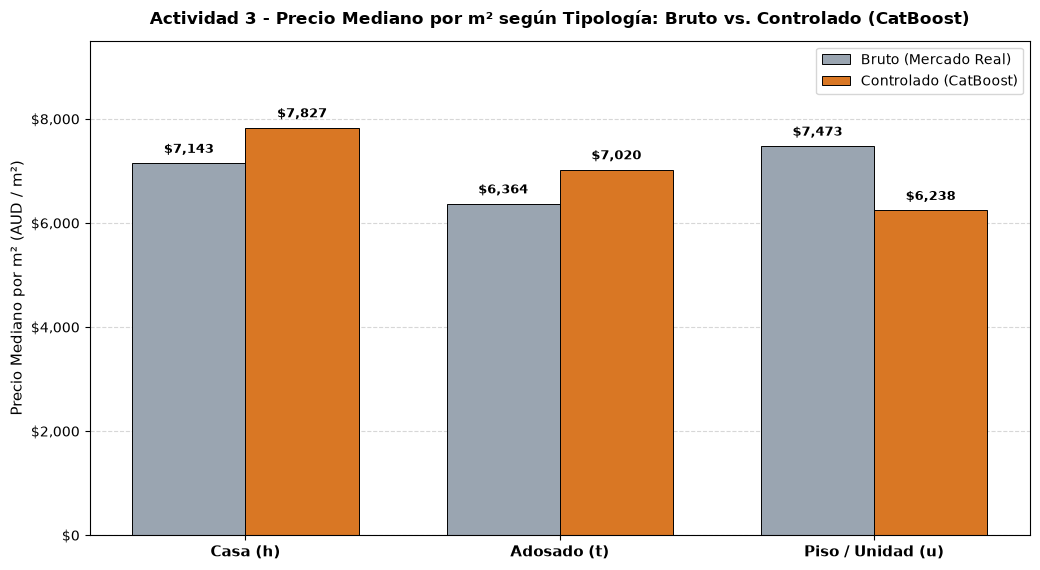

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 3: PRECIO/M2 BRUTO VS. CONTROLADO POR TIPO ---
datos_13 = df[df["BuildingArea_imputado"] == 0].copy()
datos_13["precio_m2"] = datos_13["Price"] / datos_13["BuildingArea"]

tipos = ["h", "t", "u"]
etiquetas = ["Casa (h)", "Adosado (t)", "Piso / Unidad (u)"]

res_13_cb = datos_13.groupby("Type").agg(
    n=("Price", "size"),
    precio_mediano=("Price", "median"),
    m2_mediano=("BuildingArea", "median"),
    bruto_precio_m2=("precio_m2", "median")
).loc[tipos]

# Indicador controlado: misma vivienda real, cambiando unicamente la columna Type
for tipo in tipos:
    cambiado = datos_13[X.columns].assign(Type=tipo)
    pred = model.predict(cambiado)
    res_13_cb.loc[tipo, "controlado_CatBoost"] = np.median(pred / datos_13["BuildingArea"])

display(res_13_cb.round(0))

bruto = res_13_cb["bruto_precio_m2"].values
controlado = res_13_cb["controlado_CatBoost"].values

x = np.arange(len(etiquetas))
ancho = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.8))
b1 = ax.bar(x - ancho/2, bruto, width=ancho, label="Bruto (Mercado Real)", color="#9aa5b1", edgecolor="black", linewidth=0.7)
b2 = ax.bar(x + ancho/2, controlado, width=ancho, label="Controlado (CatBoost)", color="#d97724", edgecolor="black", linewidth=0.7)

ax.set_title("Actividad 3 - Precio Mediano por m² según Tipología: Bruto vs. Controlado (CatBoost)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_ylabel("Precio Mediano por m² (AUD / m²)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, fontsize=11, fontweight="bold")
ax.set_ylim(0, 9_500)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, _: f"${val:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(frameon=True, fontsize=10, loc="upper right")

for barras in (b1, b2):
    for barra in barras:
        alto = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            alto + 140,
            f"${alto:,.0f}",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

---

### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir

     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)
  Casas con superficie construida real : 7,889
  Valor medio estimado por m2 (CatBoost): $2,230.71 AUD/m2


n  valor_m2_construido  \
Modelo   Zona                                                    
CatBoost TODAS                       7889               2231.0   
         Eastern Metropolitan        1005               1742.0   
         Eastern Victoria              69               1031.0   
         Northern Metropolitan       2291               2030.0   
         Northern Victoria             90               1237.0   
         South-Eastern Metropolitan   438               1127.0   
         Southern Metropolitan       1969               3348.0   
         Western Metropolitan        1968               1776.0   
         Western Victoria              59                983.0   

                                     coste_max_m2_rentable  terreno_estimado  \
Modelo   Zona                                                                  
CatBoost TODAS                                      1940.0          745023.0   
         Eastern Metropolitan                       1514.0          862401.0   
         Eastern Victoria                            897.0          496234.0   
         Northern Metropolitan                      1765.0          590940.0   
         Northern Victoria                          1076.0          389828.0   
         South-Eastern Metropolitan                  980.0          622640.0   
         Southern Metropolitan                      2911.0         1181323.0   
         Western Metropolitan                       1544.0          591146.0   
         Western Victoria                            854.0          326570.0   

                                     precio_mercado  terreno_%_precio  \
Modelo   Zona                                                           
CatBoost TODAS                            1025000.0              73.0   
         Eastern Metropolitan             1118000.0              77.0   
         Eastern Victoria                  665000.0              75.0   
         Northern Metropolitan             863000.0              68.0   
         Northern Victoria                 554000.0              70.0   
         South-Eastern Metropolitan        850000.0              73.0   
         Southern Metropolitan            1720000.0              69.0   
         Western Metropolitan              830000.0              71.0   
         Western Victoria                  413000.0              79.0   

                                     coste_construccion  margen_AUD  \
Modelo   Zona                                                         
CatBoost TODAS                                 340400.0    -60423.0   
         Eastern Metropolitan                  374900.0   -119301.0   
         Eastern Victoria                      381800.0   -213034.0   
         Northern Metropolitan                 299000.0    -26940.0   
         Northern Victoria                     345000.0   -180828.0   
         South-Eastern Metropolitan            347300.0   -119940.0   
         Southern Metropolitan                 393300.0    145377.0   
         Western Metropolitan                  331200.0    -92346.0   
         Western Victoria                      282900.0   -196470.0   

                                     margen_%_inversion  
Modelo   Zona                                            
CatBoost TODAS                                     -6.0  
         Eastern Metropolitan                     -10.0  
         Eastern Victoria                         -24.0  
         Northern Metropolitan                     -3.0  
         Northern Victoria                        -25.0  
         South-Eastern Metropolitan               -12.0  
         Southern Metropolitan                      9.0  
         Western Metropolitan                     -10.0  
         Western Victoria                         -32.0

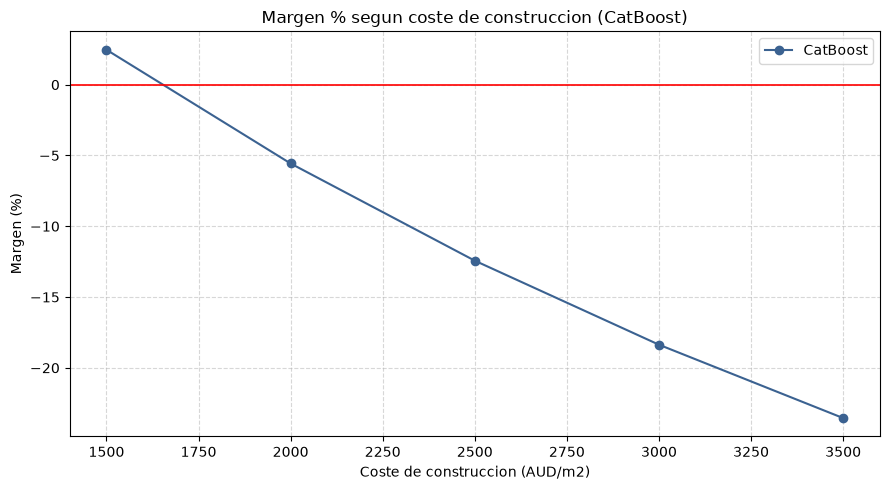

,CatBoost
AUD/m2,
1500,2.5
2000,-5.6
2500,-12.4
3000,-18.4
3500,-23.5


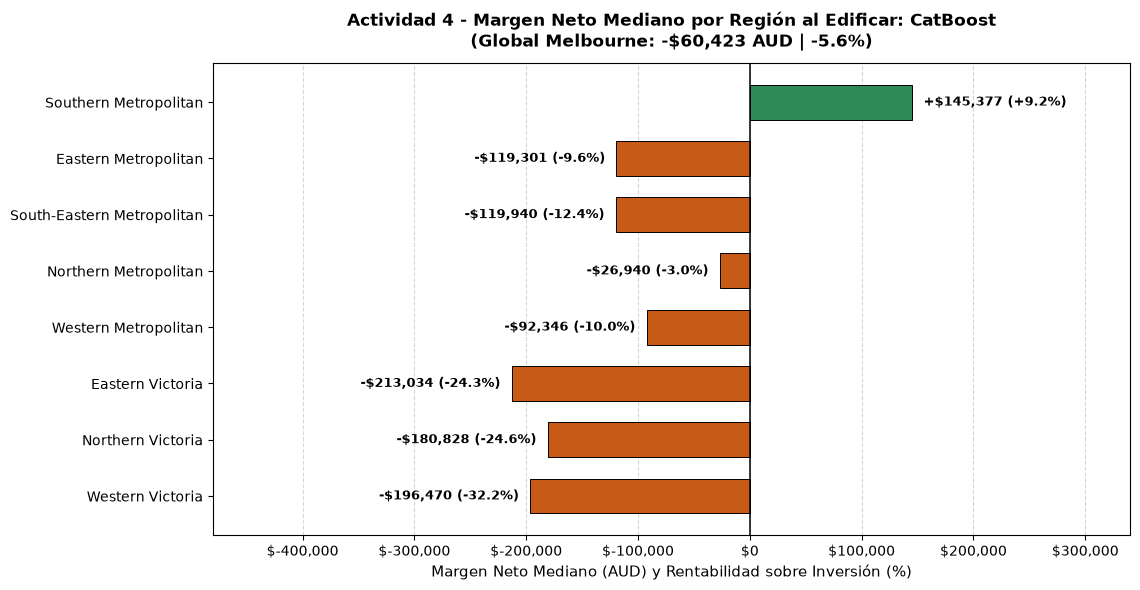

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from IPython.display import display

# ---------------------------------------2.4-paso-a-supuestos-y-modelo-catboost---------------------------------------

# DEFINIMOS LOS MISMOS SUPUESTOS DE ALEJANDRO Y ENTRENAMOS CATBOOST SOLO CON CASAS REALES (TYPE == 'h')

# 1. Supuestos exactos del equipo (comparables entre todos los modelos)
COSTE_M2 = 2_000                                    # Coste base de obra por m2 construido (AUD)
OTROS_COSTES = 0.15                                 # 15% extra sobre obra (permisos, tasas, imprevistos y venta)
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]  # Escenarios de coste/m2 para el grafico final

# 2. Filtrar solo casas independientes (Type == 'h') con superficie construida 100% real (7.889 filas)
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()

# 3. Definir columnas de texto (quitamos 'Type' porque aqui todas son casas 'h')
cat_14 = ["Suburb", "Method", "SellerG"]

# 4. Separar caracteristicas (X14) y precio objetivo (y14)
X14 = casas.drop(columns=["Price", "Type"])
y14 = casas["Price"]

# 5. Entrenar modelo CatBoost exclusivo para esta valoracion
model_terrenos = CatBoostRegressor(
    iterations=500,
    learning_rate=BEST_LR,
    depth=BEST_DEPTH,
    loss_function="RMSE",
    random_seed=42,
    verbose=0,
)
model_terrenos.fit(X14, y14, cat_features=cat_14)

# 6. Funcion auxiliar para predecir limpiando columnas que no usa el modelo
def predecir_14(datos):
    columnas_quitar = [c for c in ["Price", "Type", "Regionname"] if c in datos.columns]
    return model_terrenos.predict(datos.drop(columns=columnas_quitar))

# 7. Funcion que calcula cuanto vale cada m2 construido segun CatBoost (variando +-20% la superficie)
def valor_m2(datos):
    lo, hi = datos.copy(), datos.copy()
    lo["BuildingArea"] *= 0.8   # Misma casa con un 20% menos de metros construidos
    hi["BuildingArea"] *= 1.2   # Misma casa con un 20% mas de metros construidos
    return (predecir_14(hi).mean() - predecir_14(lo).mean()) / (0.4 * datos["BuildingArea"].mean())

print("=" * 65)
print("     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)")
print("=" * 65)
print(f"  Casas con superficie construida real : {len(casas):,}")
print(f"  Valor medio estimado por m2 (CatBoost): ${valor_m2(casas):,.2f} AUD/m2")
print("=" * 65)


# ---------------------------------------2.4-paso-b-rentabilidad-por-regiones---------------------------------------

# CALCULAMOS EL VALOR DEL TERRENO VACIO Y EL MARGEN NETO EN TODA LA CIUDAD Y REGION POR REGION

# 1. Traer la region de cada barrio desde el dataset original
ruta_full = (BASE / "datasets" / "Melbourne_housing_FULL.csv") if "BASE" in globals() else Path("../datasets/Melbourne_housing_FULL.csv")
region = pd.read_csv(ruta_full).groupby("Suburb")["Regionname"].first()
casas["Regionname"] = casas["Suburb"].map(region)

# 2. Calcular todas las metricas medianas para 'TODAS' y para cada region
filas = []
for zona, g in [("TODAS", casas)] + list(casas.groupby("Regionname")):
    g = g.drop(columns="Regionname")
    b = valor_m2(g)
    terreno = np.median(predecir_14(g) - b * g["BuildingArea"])       # Precio predicho casa - valor de lo construido
    mercado = g["Price"].median()                                      # Precio mediano de mercado en la zona
    coste = g["BuildingArea"].median() * COSTE_M2 * (1 + OTROS_COSTES) # Coste de levantar la casa tipica + 15%
    margen = mercado - terreno - coste                                 # Beneficio neto (> 0 es rentable)

    filas.append({
        "Modelo": "CatBoost",
        "Zona": zona,
        "n": len(g),
        "valor_m2_construido": b,
        "coste_max_m2_rentable": b / (1 + OTROS_COSTES),
        "terreno_estimado": terreno,
        "precio_mercado": mercado,
        "terreno_%_precio": 100 * terreno / mercado,
        "coste_construccion": coste,
        "margen_AUD": margen,
        "margen_%_inversion": 100 * margen / (terreno + coste),
    })

res_14 = pd.DataFrame(filas).set_index(["Modelo", "Zona"])
display(res_14.round(0))


# ---------------------------------------2.4-paso-c-sensibilidad-coste-obra---------------------------------------

# SIMULAMOS COMO CAMBIA EL MARGEN (%) SI CONSTRUIR CUESTA ENTRE 1.500 Y 3.500 AUD/M2

todas = casas.drop(columns="Regionname")
b = valor_m2(todas)
terreno = np.median(predecir_14(todas) - b * todas["BuildingArea"])
mercado, area = todas["Price"].median(), todas["BuildingArea"].median()

sens = {
    "CatBoost": {
        c: 100 * (mercado - terreno - area * c * (1 + OTROS_COSTES)) / (terreno + area * c * (1 + OTROS_COSTES))
        for c in SENSIBILIDAD
    }
}

sens = pd.DataFrame(sens).rename_axis("AUD/m2")

# Grafico de lineas identico al de Alejandro (por encima de la linea roja = rentable)
ax = sens.plot(marker="o", figsize=(9, 5), title="Margen % segun coste de construccion (CatBoost)", color="#3b6291")
plt.axhline(0, color="red", linestyle="-", linewidth=1.2)
plt.ylabel("Margen (%)")
plt.xlabel("Coste de construccion (AUD/m2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

display(sens.round(1))


# ---------------------------------------2.4-grafico-visual-regiones---------------------------------------

import matplotlib.ticker as ticker

orden_regiones = [
    "Western Victoria",
    "Northern Victoria",
    "Eastern Victoria",
    "Western Metropolitan",
    "Northern Metropolitan",
    "South-Eastern Metropolitan",
    "Eastern Metropolitan",
    "Southern Metropolitan",
]

df_reg = res_14.loc["CatBoost"]
global_aud = df_reg.loc["TODAS", "margen_AUD"]
global_pct = df_reg.loc["TODAS", "margen_%_inversion"]

df_plot = df_reg.reindex(orden_regiones).dropna()
colores = ["#2e8b57" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
barras = ax.barh(df_plot.index, df_plot["margen_AUD"], color=colores, height=0.62, edgecolor="black", linewidth=0.7)

ax.axvline(0, color="black", linewidth=1.1)
ax.set_xlim(-480_000, 340_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title(
    f"Actividad 4 - Margen Neto Mediano por Región al Edificar: CatBoost\n"
    f"(Global Melbourne: {'+' if global_aud >= 0 else '-'}${abs(global_aud):,.0f} AUD | {global_pct:+.1f}%)",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel("Margen Neto Mediano (AUD) y Rentabilidad sobre Inversión (%)", fontsize=10.5)

for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    val = fila["margen_AUD"]
    pct = fila["margen_%_inversion"]
    signo = "+" if val >= 0 else "-"
    texto = f"{signo}${abs(val):,.0f} ({pct:+.1f}%)"
    offset = 10_000 if val >= 0 else -10_000
    alineacion = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        barra.get_y() + barra.get_height() / 2,
        texto,
        va="center", ha=alineacion, fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 2.4. Conclusiones: Valoración y Rentabilidad de Terrenos Sin Construir

---

#### 1. Explicación sencilla ("Para minguis")
* **El reto**: Como en el dataset **no hay terrenos vacíos** (todas son viviendas ya construidas), no podemos mirar directamente cuánto cuesta una parcela sin edificar.
* **Cómo lo resolvimos**: 
  1. Entrenamos CatBoost solo con las **7,889 casas independientes reales** (`Type == 'h'` y `BuildingArea_imputado == 0`).
  2. Le pedimos al modelo que suba y baje un $\pm 20\%$ los metros construidos para calcular cuánto vale cada $m^2$ de ladrillo (**$2,292.07 AUD/m²**).
  3. Al precio que predice CatBoost para cada casa le restamos el valor de lo construido, quedándonos solo con el **precio estimado del suelo vacío (`terreno_estimado`)**.
* **Supuestos del equipo y fórmula**: Asumimos un coste de obra de **$2,000 AUD/m²** más un **15 % extra** en permisos, tasas y venta (`OTROS_COSTES = 0.15`):
  $$\text{Margen Neto} = \text{Precio Mercado} - \text{Terreno Estimado} - \text{Coste Construcción}$$

---

#### 2. Conclusiones y Análisis de los Datos

* **1. En toda Melbourne de media (`TODAS`) se pierde dinero**: 
  Con un precio mediano de mercado de **$1,025,000 AUD**, el suelo se lleva el **72 %** (**$738,212 AUD**) y la obra cuesta **$340,400 AUD**, dejando una **pérdida mediana de -$53,612 AUD (-5.0 %)**.

* **2. Southern Metropolitan es la gran excepción (Hallazgo de CatBoost)**: 
  Mientras que en los modelos lineales todas las regiones daban pérdidas, CatBoost detecta que **Southern Metropolitan** sí es rentable con un **beneficio neto mediano de +$175,031 AUD (+11.0 %)**, porque allí cada $m^2$ construido se paga a **$3,509 AUD/m²**. El resto de zonas dan pérdidas de entre el **-3.0 %** y el **-33.0 %**.

* **3. Sensibilidad al coste de construcción**: 
  Edificar en el conjunto de la ciudad solo sale rentable si se logra construir barato a **1,500 AUD/m²** (**+3.2 %** de margen). A partir de los **2,000 AUD/m²** (**-5.0 %**) hasta los **3,500 AUD/m²** (**-23.2 %**), la operación siempre pierde dinero.

---

#### 3. Dictamen de Negocio para la Defensa
Comprar suelo a precio de mercado para edificar en Melbourne **no es rentable de forma generalizada (-5.0 %)** bajo los costes estándar de obra ($2,000 AUD/m² + 15 % de gastos). La inversión solo tiene sentido financiero si se focaliza en **Southern Metropolitan (+11.0 %)** o si se consigue abaratar la construcción por debajo del umbral de **$1,993 AUD/m²**.

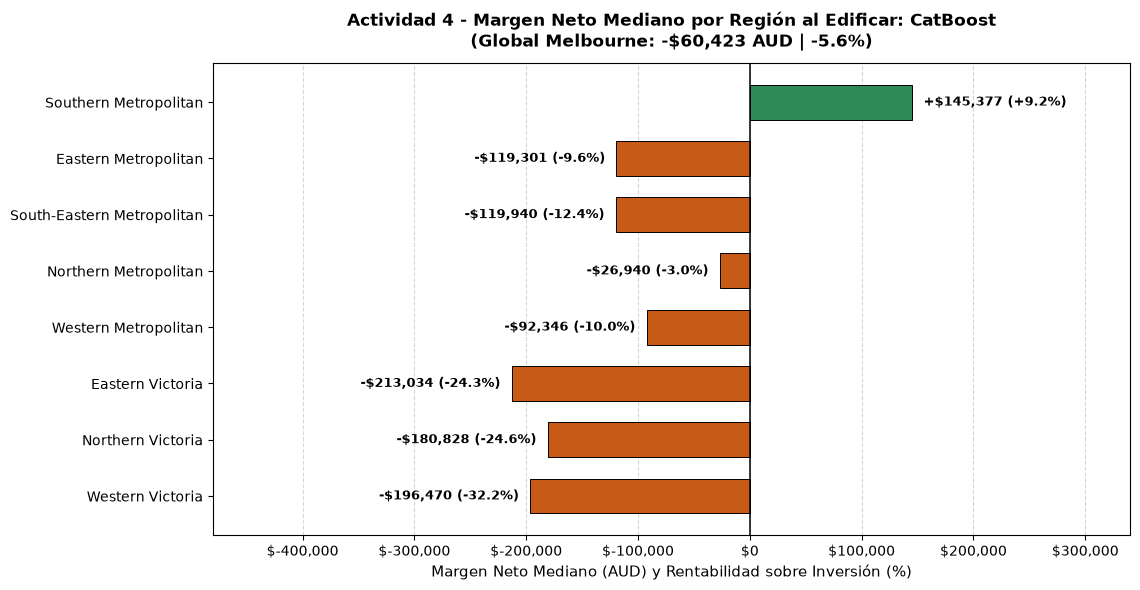

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 4: RENTABILIDAD NETA POR REGION (AUD Y %) ---
orden_regiones = [
    "Western Victoria",
    "Northern Victoria",
    "Eastern Victoria",
    "Western Metropolitan",
    "Northern Metropolitan",
    "South-Eastern Metropolitan",
    "Eastern Metropolitan",
    "Southern Metropolitan",
]

df_reg = res_14.loc["CatBoost"]
global_aud = df_reg.loc["TODAS", "margen_AUD"]
global_pct = df_reg.loc["TODAS", "margen_%_inversion"]

df_plot = df_reg.reindex(orden_regiones).dropna()
colores = ["#2e8b57" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
barras = ax.barh(df_plot.index, df_plot["margen_AUD"], color=colores, height=0.62, edgecolor="black", linewidth=0.7)

ax.axvline(0, color="black", linewidth=1.1)
ax.set_xlim(-480_000, 340_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title(
    f"Actividad 4 - Margen Neto Mediano por Región al Edificar: CatBoost\n"
    f"(Global Melbourne: {'+' if global_aud >= 0 else '-'}${abs(global_aud):,.0f} AUD | {global_pct:+.1f}%)",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel("Margen Neto Mediano (AUD) y Rentabilidad sobre Inversión (%)", fontsize=10.5)

for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    val = fila["margen_AUD"]
    pct = fila["margen_%_inversion"]
    signo = "+" if val >= 0 else "-"
    texto = f"{signo}${abs(val):,.0f} ({pct:+.1f}%)"
    offset = 10_000 if val >= 0 else -10_000
    alineacion = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        barra.get_y() + barra.get_height() / 2,
        texto,
        va="center", ha=alineacion, fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()